In [ ]:
# to ignore the warnings
import warnings
warnings.filterwarnings("ignore")

In [ ]:
from google.colab import drive
drive.mount('')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
!unzip '/content/drive/MyDrive/plant_leaf_classification/dataset-disease.zip'

Streaming output truncated to the last 5000 lines.
  inflating: plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/08c033bd-fbc3-445a-88d1-1863070e52ce___YLCV_GCREC 2872.JPG  
  inflating: plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/08dd176c-e9d9-4746-92c3-fa8dc9074347___UF.GRC_YLCV_Lab 03057.JPG  
  inflating: plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/08f78a80-46f5-45a6-937c-4d05d61c08c2___UF.GRC_YLCV_Lab 01895.JPG  
  inflating: plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/0903aa95-6e8a-4abd-a003-126fcd9a5493___YLCV_GCREC 2806.JPG  
  inflating: plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/0911d416-d73d-4c2a-8e45-207a7ceb7c9a___YLCV_GCREC 2773.JPG  
  inflating: plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/09188838-cc89-4925-94c5-d9563c4cb4bf___UF.GRC_YLCV_Lab 02974.JPG  
  inflating: plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus/0922e026-b563-438d-b9ed-74

In [ ]:
import pandas as pd
import numpy as np
import os
import shutil
import glob
import matplotlib.pyplot as plt

In [ ]:
train_path  = "/content/plantvillage/PlantVillage"
#valid_path  = ""
test_path   = "/content/plantvillage/PlantVillage"
print("splited")

splited


In [ ]:

from keras.preprocessing.image import ImageDataGenerator
from keras.applications import vgg16
from keras.models import Model
from keras.layers import Dense, MaxPool2D, Conv2D
import keras

In [ ]:
train_data_gen = ImageDataGenerator(preprocessing_function= vgg16.preprocess_input , zoom_range= 0.2, horizontal_flip= True, shear_range= 0.2 , rescale= 1./255)
train = train_data_gen.flow_from_directory(directory= train_path , target_size=(224,224))

Found 20638 images belonging to 15 classes.


In [ ]:
test_data_gen = ImageDataGenerator(preprocessing_function= vgg16.preprocess_input, rescale= 1./255 )
test = train_data_gen.flow_from_directory(directory= test_path , target_size=(224,224), shuffle= False)

Found 20638 images belonging to 15 classes.


In [ ]:
train.class_indices

{'Pepper__bell___Bacterial_spot': 0,
 'Pepper__bell___healthy': 1,
 'Potato___Early_blight': 2,
 'Potato___Late_blight': 3,
 'Potato___healthy': 4,
 'Tomato_Bacterial_spot': 5,
 'Tomato_Early_blight': 6,
 'Tomato_Late_blight': 7,
 'Tomato_Leaf_Mold': 8,
 'Tomato_Septoria_leaf_spot': 9,
 'Tomato_Spider_mites_Two_spotted_spider_mite': 10,
 'Tomato__Target_Spot': 11,
 'Tomato__Tomato_YellowLeaf__Curl_Virus': 12,
 'Tomato__Tomato_mosaic_virus': 13,
 'Tomato_healthy': 14}

In [ ]:
class_type = {0:'Pepper__bell___Bacterial_spot',
 1:'Pepper__bell___healthy',
 2:'Potato___Early_blight',
 3:'Potato___Late_blight',
 4:'Potato___healthy',
 5:'Tomato_Bacterial_spot',
 6:'Tomato_Early_blight',
 7:'Tomato_Late_blight',
 8:'Tomato_Leaf_Mold',
 9:'Tomato_Septoria_leaf_spot',
 10:'Tomato_Spider_mites_Two_spotted_spider_mite',
 11:'Tomato__Target_Spot',
 12:'Tomato__Tomato_YellowLeaf__Curl_Virus',
 13:'Tomato__Tomato_mosaic_virus',
 14:'Tomato_healthy'}

In [ ]:
t_img , label = train.next()

In [ ]:
def plotImages(img_arr, label):

  for im, l in zip(img_arr,label) :
    plt.figure(figsize= (5,5))
    plt.imshow(im, cmap = 'gray')
    plt.title(im.shape)
    plt.axis = False
    plt.show()

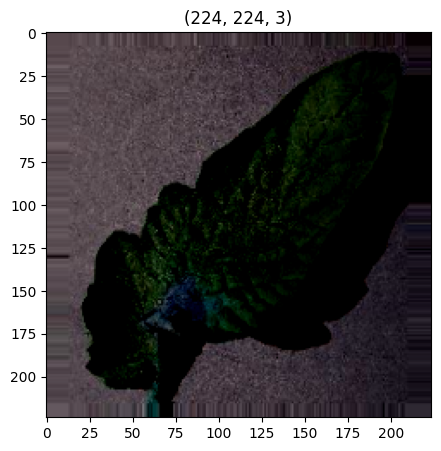

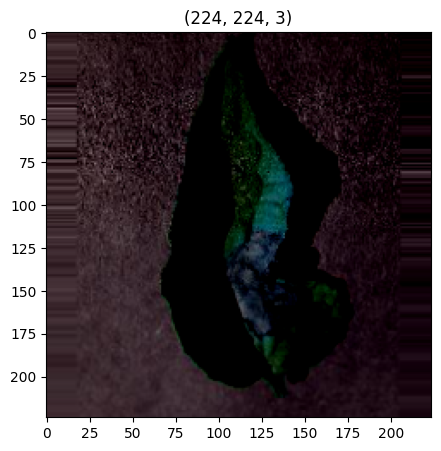

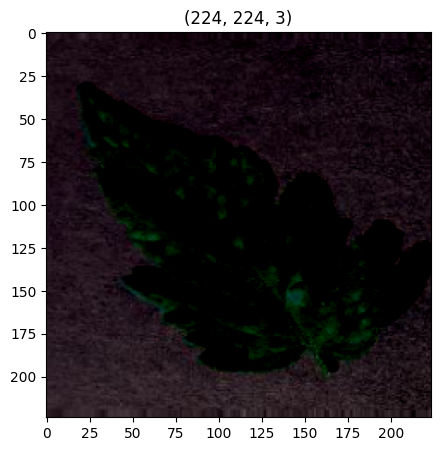

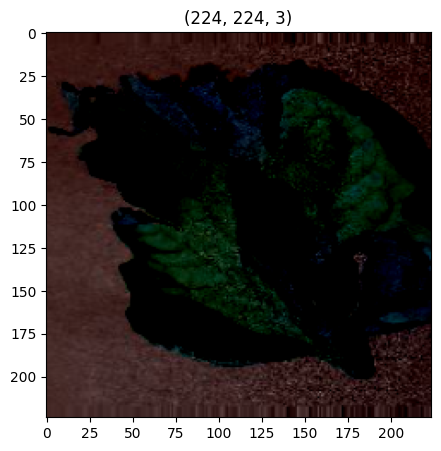

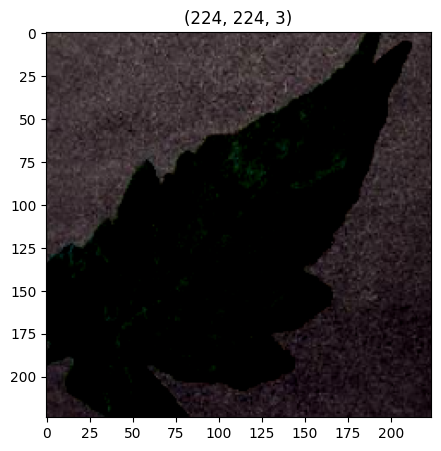

...

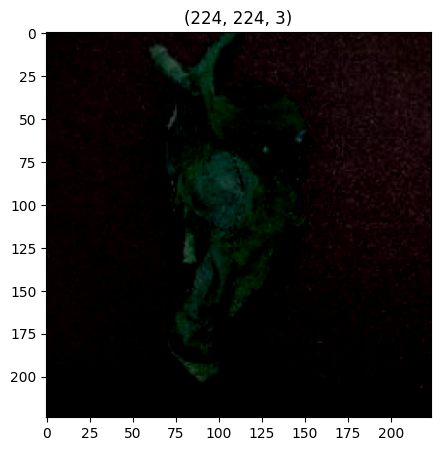

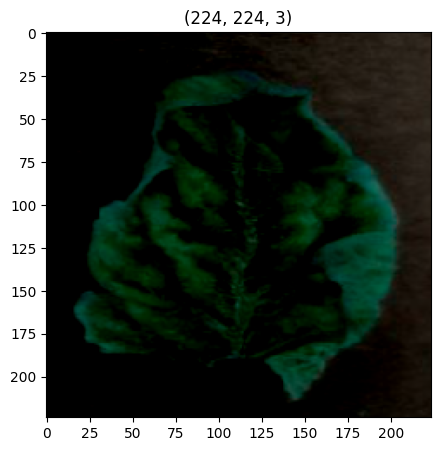

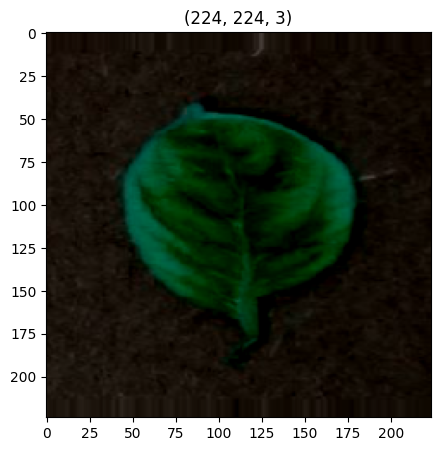

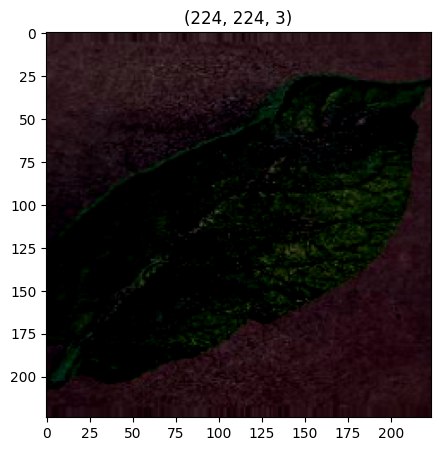

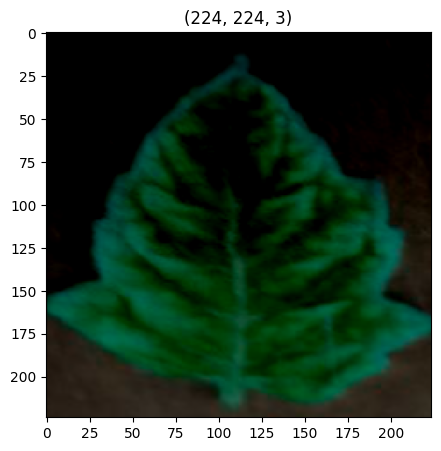

In [ ]:
plotImages(t_img, label)

In [ ]:
from keras.applications.vgg16 import VGG16
from keras.layers import Flatten , Dense, Dropout , MaxPool2D

In [ ]:
from keras.applications.vgg16 import VGG16
from keras.layers import Flatten , Dense, Dropout , MaxPool2D

In [ ]:
vgg = VGG16( input_shape=(224,224,3), include_top= False) # include_top will consider the new weights

58889256/58889256 [==============================] - 4s 0us/step


In [ ]:
for layer in vgg.layers:           # Dont Train the parameters again
  layer.trainable = False

In [ ]:
x = Flatten()(vgg.output)
x = Dense(units=15, activation='softmax', name = 'predictions')(x)

model = Model(vgg.input, x)

In [ ]:
model.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)     147584    
                                                                 
 block2_pool (MaxPooling2D)  (None, 56, 56, 128)       0   

In [ ]:
model.compile(optimizer='adam', loss = 'categorical_crossentropy', metrics=['accuracy'])

In [ ]:
# implementing early stopping and model check point

from keras.callbacks import EarlyStopping
from keras.callbacks import ModelCheckpoint

es = EarlyStopping(monitor= "val_accuracy" , min_delta= 0.01, patience= 3, verbose=1)
mc = ModelCheckpoint(filepath="bestmodel.h5", monitor="val_accuracy", verbose=1, save_best_only= False)

In [ ]:
#hist = model.fit_generator(train, steps_per_epoch= 10, epochs= 8, validation_data= valid , validation_steps= 32)
hist = model.fit_generator(train, steps_per_epoch= 10, epochs=20 , validation_data= test , validation_steps= 32, callbacks=[mc])

Epoch 1/20
10/10 [==============================] - ETA: 0s - loss: 3.2576 - accuracy: 0.2219
Epoch 1: saving model to bestmodel.h5
10/10 [==============================] - 28s 3s/step - loss: 3.2576 - accuracy: 0.2219 - val_loss: 3.2156 - val_accuracy: 0.0088
Epoch 2/20
10/10 [==============================] - ETA: 0s - loss: 1.9609 - accuracy: 0.5094
Epoch 2: saving model to bestmodel.h5
10/10 [==============================] - 26s 3s/step - loss: 1.9609 - accuracy: 0.5094 - val_loss: 0.7235 - val_accuracy: 0.7979
Epoch 3/20
10/10 [==============================] - ETA: 0s - loss: 1.5172 - accuracy: 0.5781
Epoch 3: saving model to bestmodel.h5
10/10 [==============================] - 26s 3s/step - loss: 1.5172 - accuracy: 0.5781 - val_loss: 0.7727 - val_accuracy: 0.7148
Epoch 4/20
10/10 [==============================] - ETA: 0s - loss: 1.3293 - accuracy: 0.5844
Epoch 4: saving model to bestmodel.h5
10/10 [==============================] - 26s 3s/step - loss: 1.3293 - accuracy: 0.584

In [ ]:
## load only the best model
from keras.models import load_model
model = load_model("bestmodel.h5")

In [ ]:
h = hist.history
h.keys()

dict_keys(['loss', 'accuracy', 'val_loss', 'val_accuracy'])

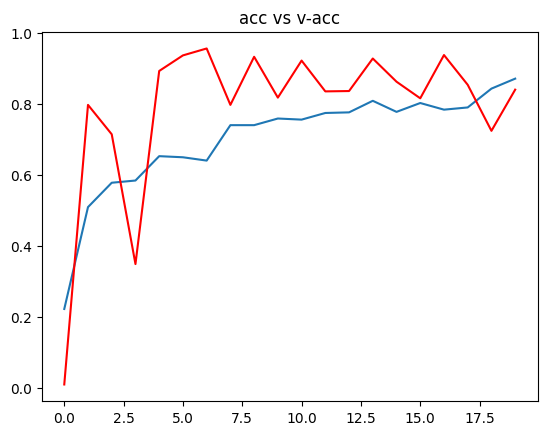

In [ ]:
plt.plot(h['accuracy'])
plt.plot(h['val_accuracy'] , c = "red")
plt.title("acc vs v-acc")
plt.show()

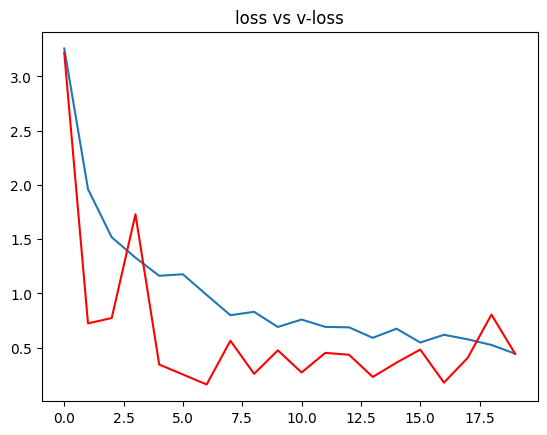

In [ ]:
plt.plot(h['loss'])
plt.plot(h['val_loss'] , c = "red")
plt.title("loss vs v-loss")
plt.show()

In [ ]:
from keras.preprocessing import image

def get_img_array(img_path):
  """
  Input : Takes in image path as input
  Output : Gives out Pre-Processed image
  """
  path = img_path

  img = keras.utils.load_img(path, target_size=(224,224,3))

  img = keras.utils.img_to_array(img)/255
  img = np.expand_dims(img , axis= 0 )

  return img

In [ ]:
# checking out the accuracy of our model

acc = model.evaluate_generator(generator= test)[1]

print(f"The accuracy of your model is = {acc} %")

1/1 [==============================] - 1s 719ms/step
The given  image is of type = Potato___Early_blight



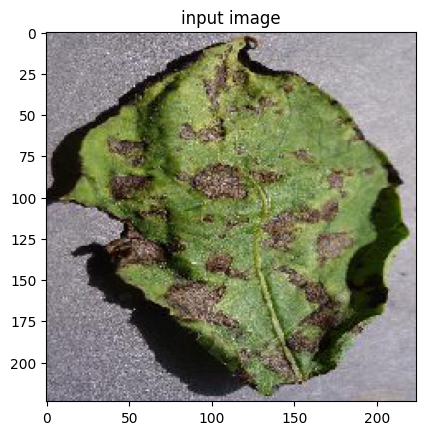

In [ ]:
# path for that new image. ( you can take it either from google or any other scource)

path = "/content/PlantVillage/Potato___Early_blight/001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 20ms/step
The given  image is of type = Pepper__bell___healthy



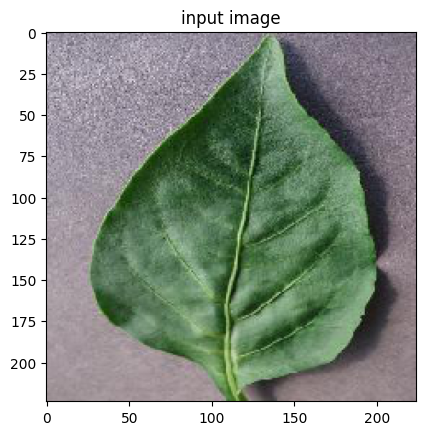

In [ ]:

path = "/content/PlantVillage/Pepper__bell___healthy/002f87b7-e1a5-49e5-a422-bb423630ded5___JR_HL 8068.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 19ms/step
The given  image is of type = Potato___Early_blight



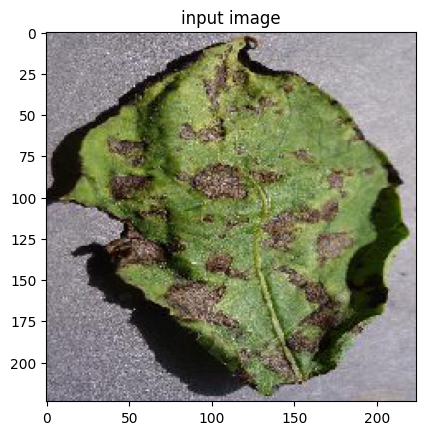

In [ ]:

path = "/content/PlantVillage/Potato___Early_blight/001187a0-57ab-4329-baff-e7246a9edeb0___RS_Early.B 8178.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 30ms/step
The given  image is of type = Tomato__Tomato_mosaic_virus



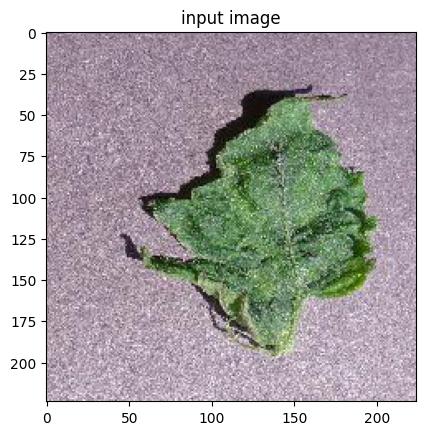

In [ ]:

path = "/content/PlantVillage/Tomato__Tomato_mosaic_virus/01b32f27-2b9b-4961-805b-8066bf4d90f1___PSU_CG 2417.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 29ms/step
The given  image is of type = Tomato_Spider_mites_Two_spotted_spider_mite



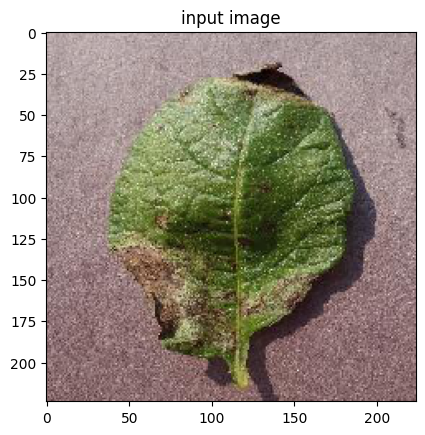

In [ ]:

path = "/content/PlantVillage/Potato___Late_blight/00b1f292-23dd-44d4-aad3-c1ffb6a6ad5a___RS_LB 4479.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 19ms/step
The given  image is of type = Tomato_Spider_mites_Two_spotted_spider_mite



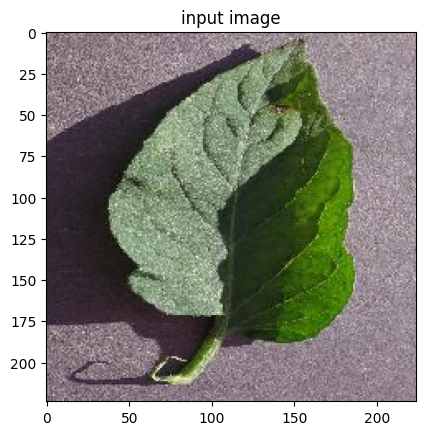

In [ ]:

path = "/content/PlantVillage/Tomato__Target_Spot/002213fb-b620-4593-b9ac-6a6cc119b100___Com.G_TgS_FL 8360.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 49ms/step
The given  image is of type = Tomato_Early_blight



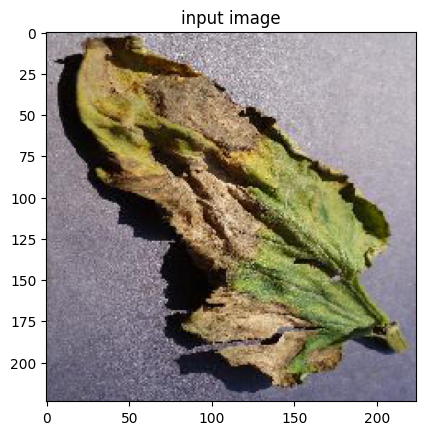

In [ ]:

path = "/content/PlantVillage/Tomato_Late_blight/031ab3ab-02f4-4397-9886-54345461580d___RS_Late.B 6654.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 33ms/step
The given  image is of type = Tomato__Tomato_YellowLeaf__Curl_Virus



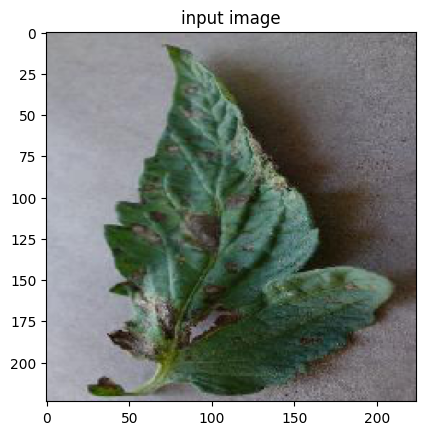

In [ ]:

path = "/content/PlantVillage/Tomato_Early_blight/079e0d43-e9d2-4217-b8e8-2f3b989cdab2___RS_Erly.B 7588.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()

1/1 [==============================] - 0s 20ms/step
The given  image is of type = Tomato_healthy



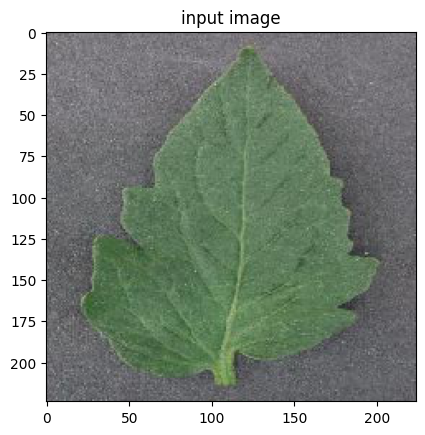

In [ ]:

path = "/content/PlantVillage/Tomato_healthy/0184dc6b-bfc1-4515-ac59-bbadaf524e1a___GH_HL Leaf 422.1.JPG"       # you can add any image path

#predictions: path:- provide any image from google or provide image from all image folder
img = get_img_array(path)

res = class_type[np.argmax(model.predict(img))]
print(f"The given  image is of type = {res}")
print()

# to display the image
plt.imshow(img[0], cmap = "gray")
plt.title("input image")
plt.show()